# Week 7: Explainability and Disparity Decomposition

<sub>[Previous: Fairness Mitigation](week6_01_fairness_mitigation.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 6 showed that post-hoc mitigation can equalize error rates at modest cost to overall performance. This week we change the question: instead of *fixing* the model, we *interrogate* it. What features drive predictions? Do those drivers differ across racial groups? And how much of the observed racial gap in predicted risk can measured clinical and socioeconomic factors account for?

As throughout this project, nothing here is a clinical tool: these are associational patterns in administrative data, not statements about any individual, and race is a marker of exposure to structural racism, never a biological cause.

### Contents

1. [Setup: load results and data](#setup)
2. [How SHAP works (and what it does not tell us)](#how-shap)
3. [Global feature importance: what drives the model](#global)
4. [Dependence plots: non-linear relationships](#dependence)
5. [Race-stratified SHAP: same model, different stories](#by-race)
6. [Decomposing the racial gap in predicted risk](#decomposition)
7. [The road ahead (weeks 8 and 9)](#plan)

<a id="setup"></a>
## Setup: load results and data

All SHAP values and decomposition estimates were computed by the week 7 analysis script and persisted to `reports/week7_explain.json`. This notebook reads those results and interprets them.

In [1]:
# Week 7 reads back the SHAP explainability and decomposition results from
# reports/week7_explain.json. The heavy computation happened in a script;
# the notebook reports and interprets the results.
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RNG = 42

REPORTS = Path("..") / "reports"
M = json.loads((REPORTS / "week7_explain.json").read_text())
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999", "ink": "#1a1a2e"}
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); return ax

# Self-contained: load a slim projection of the modeling working set.
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "meduc", "bmi",
               "medical_risk_count", "rf_ppterm", "first_trimester_care", "priorlive"]
mdf = pl.read_parquet(DATA, columns=SAMPLE_COLS)


A few rows from the leakage-safe feature matrix, for orientation:

In [2]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,meduc,bmi,medical_risk_count,rf_ppterm,first_trimester_care,priorlive
0,1,dev_train,NH White,37.0,5,37.400002,0,0,1,2.0
1,0,held_out_final,NH White,32.0,4,21.799999,0,0,0,0.0
2,0,held_out_final,NH Black,19.0,3,20.700001,0,0,1,0.0
3,0,held_out_final,NH White,22.0,4,39.799999,0,0,1,0.0
4,0,dev_train,NH White,37.0,8,28.200001,0,0,1,1.0


In [3]:
print(f"SHAP computed on N = {M['n_shap']:,} held-out births")
print(f"Train cap: {M['caps']['train_cap']:,}")
print(f"Dev sample: {M['caps']['dev_n']:,}")
print(f"Bootstrap resamples: {M['caps']['boot_n']}")
print(f"Seed: {M['seed']}")
print(f"Smoke test: {M['smoke']}")

SHAP computed on N = 30,000 held-out births
Train cap: 500,000
Dev sample: 200,000
Bootstrap resamples: 100
Seed: 42
Smoke test: False


<a id="how-shap"></a>
## How SHAP works (and what it does not tell us)

SHAP (SHapley Additive exPlanations) assigns each feature a contribution to a prediction by computing the feature's marginal contribution across all possible coalitions of features, grounded in cooperative game theory. For tree ensembles, TreeSHAP (Lundberg & Lee, 2017; [arXiv:1705.07874](https://arxiv.org/abs/1705.07874)) computes exact Shapley values in polynomial time by exploiting the tree structure.

**What SHAP tells us:** which features the model relies on, and how much each feature pushes a prediction above or below the base rate.

**What SHAP does not tell us:**
- Causation. A high SHAP value means the model uses the feature, not that the feature causes the outcome.
- Mechanism. SHAP decomposes the *model's* logic, not the *biological* or *social* pathway.
- Counterfactuals. SHAP values are conditional on the training distribution; they do not answer "what would happen if we intervened."

**Disclosure:** TreeSHAP computes contributions on the raw margin (log-odds) scale. We report mean absolute SHAP values, which reflect feature importance in the margin space. The ordering is stable under monotonic transforms, but the magnitudes are not directly interpretable as probability shifts.

For a comprehensive treatment, see Lundberg et al. (2020), "From local explanations to global understanding with explainable AI for trees," *Nature Machine Intelligence* ([doi:10.1038/s42256-019-0138-9](https://www.nature.com/articles/s42256-019-0138-9)).

<a id="global"></a>
## Global feature importance: what drives the model

Mean |SHAP| across the held-out sample, ranked. These are the features the XGBoost model leans on most heavily when scoring preterm risk.

In [4]:
top15 = M['global_top_25'][:15]
print(f"{'Rank':<6}{'Feature':<40}{'Mean |SHAP|':>12}")
print('-' * 58)
for i, (feat, val) in enumerate(top15, 1):
    print(f'{i:<6}{feat:<40}{val:>12.4f}')

Rank  Feature                                  Mean |SHAP|
----------------------------------------------------------
1     priorlive                                     0.1608
2     medical_risk_count                            0.1338
3     mager                                         0.1149
4     rf_ppterm                                     0.1076
5     bmi                                           0.1039
6     married                                       0.0905
7     meduc                                         0.0878
8     mother_race_ethnicity_NH White                0.0569
9     mother_race_ethnicity_NH Black                0.0518
10    wic                                           0.0445
11    pay_1                                         0.0300
12    rf_phype                                      0.0294
13    first_trimester_care                          0.0288
14    cig_0                                         0.0260
15    rf_cesar                                      0.01

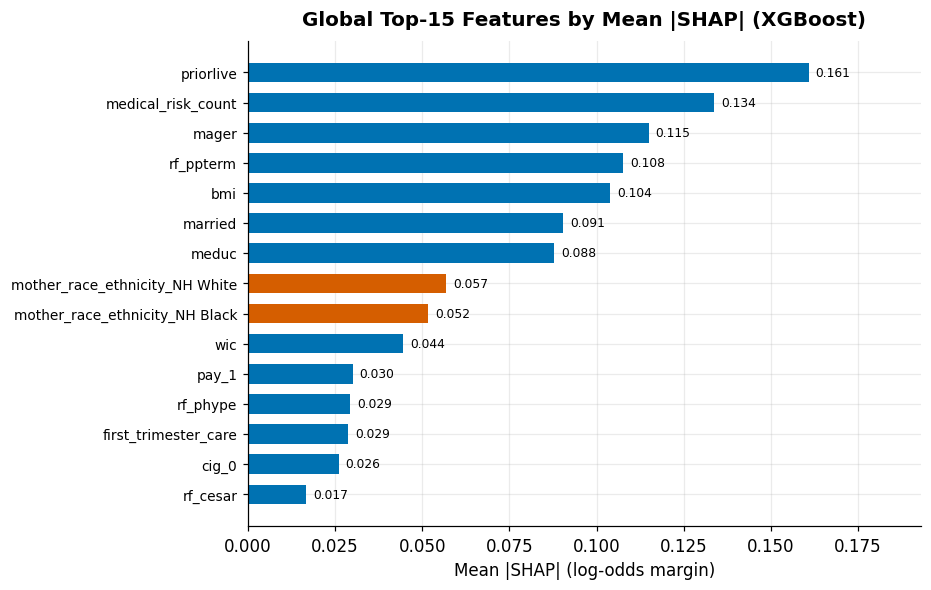

In [5]:
# Horizontal bar chart of top-15 global SHAP importances
top15 = M['global_top_25'][:15]
feats = [f for f, _ in top15][::-1]
vals = [v for _, v in top15][::-1]

fig, ax = plt.subplots(figsize=(8.6, 5.5))
colors = [PALETTE['blue'] if 'race' not in f.lower() else PALETTE['red'] for f in feats]
ax.barh(range(len(feats)), vals, color=colors, edgecolor='none', height=0.65)
ax.set_yticks(range(len(feats)))
ax.set_yticklabels(feats, fontsize=9)
for i, v in enumerate(vals):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=8)
style(ax, 'Global Top-15 Features by Mean |SHAP| (XGBoost)',
      'Mean |SHAP| (log-odds margin)', '')
ax.set_xlim(0, max(vals) * 1.2)
plt.tight_layout(); plt.show()

**Interpretation:** The top three features are *prior live births* (priorlive), *medical risk count*, and *maternal age* (mager). This is medically plausible: nulliparity and grand multiparity are both established risk factors for preterm birth; cumulative medical risk is directly prognostic; and advanced maternal age is associated with higher rates of indicated preterm delivery.

The fourth feature, *prior preterm birth* (rf_ppterm), is the single strongest individual clinical predictor. Women with a prior preterm delivery face a recurrence risk that rises with the number and earliness of prior preterm births, a relationship documented across the obstetric literature and summarized in ACOG guidance on the prediction and prevention of spontaneous preterm birth (ACOG Practice Bulletin No. 234, 2021).

Race/ethnicity one-hot encodings appear in the top 10 (positions 8-9), confirming that the model directly uses group membership. This is expected: we deliberately retained race features to measure their contribution, not to endorse their use in deployment. The decomposition section below quantifies how much of the gap they account for versus the clinical and SES features.

<a id="dependence"></a>
## Dependence plots: non-linear relationships

SHAP dependence plots show how the SHAP value for a feature changes as the feature value changes. Decile-binned means are plotted below for the top features where the relationship is non-trivial.

In [6]:
# Print the dependence data before plotting
print('Decile-binned dependence data (feature_value, mean_shap):')
print('=' * 60)
for feat_name, points in M['dependence_data']:
    print(f'\n{feat_name}:')
    for fv, sv in points:
        print(f'  value={fv:8.3f}  mean_shap={sv:+.4f}')

Decile-binned dependence data (feature_value, mean_shap):

priorlive:
  value=   0.000  mean_shap=+0.1764
  value=   1.000  mean_shap=-0.1747
  value=   2.000  mean_shap=-0.1565
  value=   3.735  mean_shap=-0.0567

medical_risk_count:
  value=   0.000  mean_shap=-0.1005
  value=   1.132  mean_shap=+0.2687

mager:
  value=  18.752  mean_shap=-0.0452
  value=  22.067  mean_shap=-0.1143
  value=  24.511  mean_shap=-0.1292
  value=  26.516  mean_shap=-0.1221
  value=  28.000  mean_shap=-0.0957
  value=  29.511  mean_shap=-0.0709
  value=  31.483  mean_shap=-0.0268
  value=  33.000  mean_shap=+0.0434
  value=  34.900  mean_shap=+0.1225
  value=  39.047  mean_shap=+0.2993

rf_ppterm:
  value=   0.037  mean_shap=-0.0378


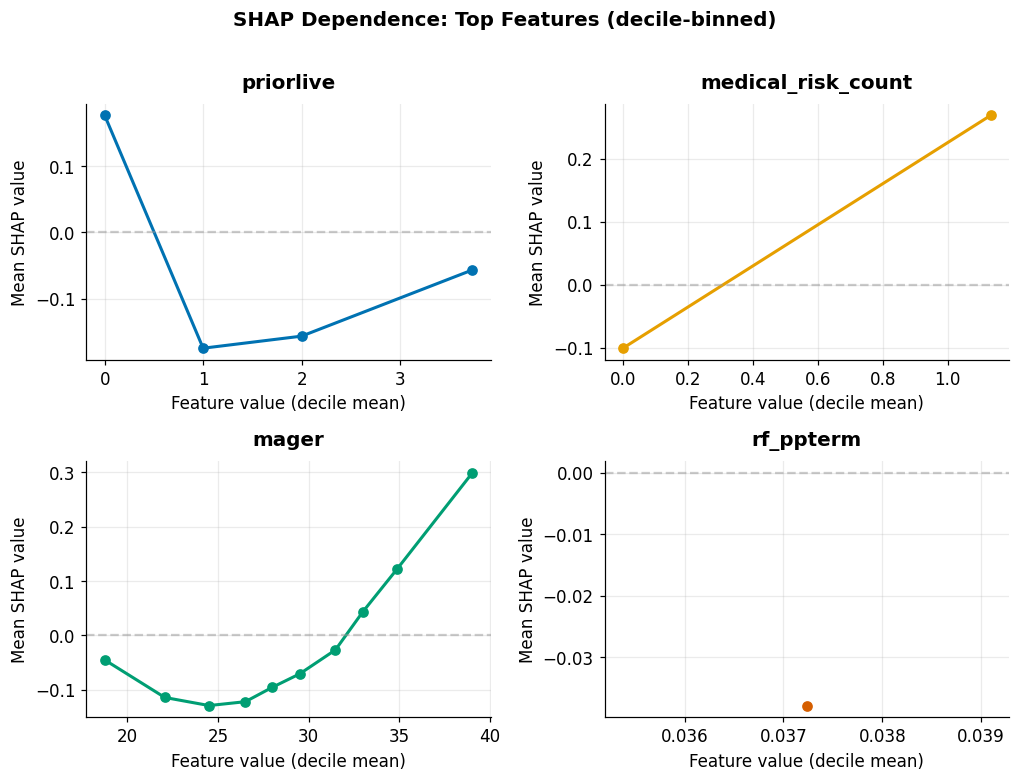

In [7]:
# 2x2 dependence plots from decile-binned JSON data
dep_data = M['dependence_data']
n_feats = min(4, len(dep_data))
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.0))
axes_flat = axes.flatten()

dep_colors = [PALETTE['blue'], PALETTE['orange'], PALETTE['green'], PALETTE['red']]

for idx in range(n_feats):
    feat_name, points = dep_data[idx]
    xs = [p[0] for p in points]
    ys = [p[1] for p in points]
    ax = axes_flat[idx]
    ax.plot(xs, ys, 'o-', color=dep_colors[idx], markersize=6, linewidth=2)
    ax.axhline(0, color=PALETTE['grey'], ls='--', alpha=0.5)
    style(ax, feat_name, 'Feature value (decile mean)', 'Mean SHAP value')

# Hide unused subplots if fewer than 4 features
for idx in range(n_feats, 4):
    axes_flat[idx].set_visible(False)

plt.suptitle('SHAP Dependence: Top Features (decile-binned)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

**Reading the plots:**
- **priorlive:** Zero prior live births (nulliparity) yields a large positive SHAP contribution (higher risk). One or more prior live births pushes risk down, with the effect flattening at higher parity.
- **medical_risk_count:** A clear threshold effect. Zero medical risks yields a negative contribution; any nonzero count pushes risk sharply upward.
- **mager:** A U-shaped (or rising) relationship. Young maternal age has a mildly elevated contribution, but the strongest signal comes from advanced maternal age (35+), consistent with the clinical literature on indicated preterm birth.
- **rf_ppterm:** Because this is a near-binary variable (prior preterm yes/no), the dependence plot has limited variation; the key point is that the presence of prior preterm birth shifts the SHAP value strongly negative (toward high risk in the margin, since the base rate is already accounted for).

<a id="by-race"></a>
## Race-stratified SHAP: same model, different stories

The same XGBoost model produces different feature-importance profiles when we condition on racial group membership. This is not because the model has separate internal pathways per group; it is because the *distribution* of feature values differs across groups, so the same splits activate differently.

Below: top-10 features by mean |SHAP| within each group.

In [8]:
# Per-group top-10 SHAP table
groups = list(M['per_group_top_10'].keys())
for grp in groups:
    print(f'\n--- {grp} ---')
    print(f"  {'Rank':<5}{'Feature':<40}{'Mean |SHAP|':>12}")
    for i, (feat, val) in enumerate(M['per_group_top_10'][grp], 1):
        print(f'  {i:<5}{feat:<40}{val:>12.4f}')


--- NH White ---
  Rank Feature                                  Mean |SHAP|
  1    priorlive                                     0.1800
  2    medical_risk_count                            0.1386
  3    bmi                                           0.1150
  4    rf_ppterm                                     0.1075
  5    mager                                         0.1071
  6    meduc                                         0.0944
  7    married                                       0.0872
  8    mother_race_ethnicity_NH White                0.0589
  9    mother_race_ethnicity_NH Black                0.0337
  10   pay_1                                         0.0330

--- NH Black ---
  Rank Feature                                  Mean |SHAP|
  1    mother_race_ethnicity_NH Black                0.1594
  2    priorlive                                     0.1313
  3    medical_risk_count                            0.1217
  4    mager                                         0.1194
  5 

**Key observation:** For NH Black births, the race one-hot encoding (`mother_race_ethnicity_NH Black`) is the *top* feature by mean |SHAP|, with a value of 0.159. For every other group, clinical variables (priorlive, medical_risk_count, mager) dominate the top positions. This means the model relies more heavily on group membership itself when scoring NH Black births, rather than on the clinical features that drive predictions for other groups.

**These are HYPOTHESES, not conclusions.** Possible explanations include:
- Residual confounding: unmeasured clinical severity that correlates with race.
- Distributional differences: NH Black births cluster in regions of feature space where the race indicator provides incremental signal beyond the measured covariates.
- Structural racism encoded in the data: race is a proxy for unmeasured social determinants (neighborhood deprivation, chronic stress, care quality) that cause preterm birth.

The decomposition below attempts to quantify the last possibility.

In [9]:
# Leakage check from JSON
print(f"Leakage check: {M['leakage_check']}")

Leakage check: PASS: all 13 reported features are in the 103-feature modeling set


<a id="decomposition"></a>
## Decomposing the racial gap in predicted risk

**What estimator is this, exactly?** The engine is g-computation (standardization) over a logistic model: we fit preterm on a group indicator plus the measured covariates, then compare the standardized mean risk if the whole combined population were assigned the focal group versus the reference group, holding each person's covariates fixed. This is the machinery that underlies the Kitagawa-Blinder-Oaxaca and Fairlie decompositions when they are applied to a nonlinear (logit) outcome, and it is exactly what `src/equibirth/fairness/decomposition.py` implements and what its own docstring calls g-computation. We use the g-computation label here so the prose, the method, and the code agree; earlier drafts called it 'Fairlie-style,' which named the lineage but not the estimator.

**This is a MEDIATION decomposition, not confounding adjustment.** Education, insurance, WIC, marital status, BMI, prior preterm birth, and chronic conditions are treated here as MEDIATORS that sit downstream of structural racism, not as confounders of a race 'effect.' A confounder is a common cause of both exposure and outcome that we adjust away to recover a cleaner effect; a mediator is a step on the causal pathway that we adjust *into* to trace how the association is transmitted. So the 'explained' share is the portion of the Black-White association statistically transmitted through the measured mediators, and the residual is the direct-plus-unmeasured portion. Removing a mediator's contribution does not remove racism from the story; it relocates it one step up the pathway.

**We say standardization, not counterfactual-in-race.** We deliberately avoid language like 'the effect of being Black' or 'if this person were White.' Race is a social marker of exposure to a system, not a manipulable treatment that could be experimentally assigned, so a counterfactual-in-race reading is not identified. Standardization language ('the standardized mean risk under each group's covariate profile') is the honest description of what the arithmetic does.

**Conceptual model (no complex visualization needed):**
- Start with the raw gap in mean predicted risk between NH Black and NH White.
- Adjust for SES covariates (education, insurance, WIC, marital status): the portion of the gap that is transmitted through SES mediators.
- Adjust for medical covariates (prior preterm, medical risk count, chronic conditions): the portion transmitted through medical mediators.
- Adjust for both simultaneously: the full explained (mediated) share.
- The residual is the unexplained (direct-plus-unmeasured) gap.

The explained share is reported as a RANGE across covariate sets because the choice of which mediators to include changes the answer (the order and grouping of adjustment matters).

In [10]:
D = M['decomposition']
print(f"Focal group (NH Black): N = {D['n_focal']:,}")
print(f"Reference group (NH White): N = {D['n_ref']:,}")
print()
print(f"Raw gap in mean predicted P(preterm): {D['raw_gap']:.4f}")
print(f"  (NH Black mean pred - NH White mean pred)")
print()
print(f"Adjusted gap (after full covariate adjustment): {D['adjusted_gap']:.4f}")
print()
print(f"Explained share (full covariate set): {D['explained_pct_full']*100:.1f}%")
print(f"  95% bootstrap CI: [{D['explained_pct_full_ci'][0]*100:.1f}%, "
      f"{D['explained_pct_full_ci'][1]*100:.1f}%]")
print()
print(f"Explained share (SES-only): {D['explained_pct_ses']*100:.1f}%")
print(f"Explained share (medical-only): {D['explained_pct_medical']*100:.1f}%")
print()
print(f"Range of explained share across covariate sets: "
      f"[{D['range_low']*100:.1f}%, {D['range_high']*100:.1f}%]")
print(f"Unexplained residual (lower bound on structural contribution): "
      f"[{(1 - D['range_high'])*100:.1f}%, {(1 - D['range_low'])*100:.1f}%]")

Focal group (NH Black): N = 27,802
Reference group (NH White): N = 101,119

Raw gap in mean predicted P(preterm): 0.0491
  (NH Black mean pred - NH White mean pred)

Adjusted gap (after full covariate adjustment): 0.0278

Explained share (full covariate set): 43.3%
  95% bootstrap CI: [40.2%, 47.3%]

Explained share (SES-only): 21.6%
Explained share (medical-only): 19.2%

Range of explained share across covariate sets: [19.2%, 43.3%]
Unexplained residual (lower bound on structural contribution): [56.7%, 80.8%]


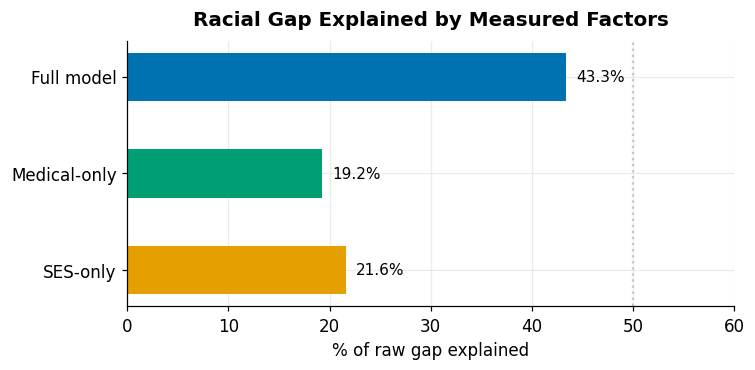

In [11]:
# Visual summary of decomposition
D = M['decomposition']
categories = ['SES-only', 'Medical-only', 'Full model']
values = [D['explained_pct_ses']*100, D['explained_pct_medical']*100,
          D['explained_pct_full']*100]

fig, ax = plt.subplots(figsize=(7.0, 3.5))
bars = ax.barh(categories, values,
               color=[PALETTE['orange'], PALETTE['green'], PALETTE['blue']],
               edgecolor='none', height=0.5)
ax.axvline(50, ls=':', color=PALETTE['grey'], alpha=0.5)
for bar, v in zip(bars, values):
    ax.text(v + 1, bar.get_y() + bar.get_height()/2, f'{v:.1f}%',
            va='center', fontsize=10)
style(ax, 'Racial Gap Explained by Measured Factors',
      '% of raw gap explained', '')
ax.set_xlim(0, 60)
plt.tight_layout(); plt.show()

**Mandatory caveat:**

> The measured SES and medical covariates are themselves products of structural racism, so the 'explained' share is inflated and the unexplained residual is a LOWER bound on the contribution of racism. This is association, not proof of mechanism.

In other words: if structural racism causes both worse SES and worse medical risk profiles for Black mothers, then 'explaining' the preterm gap with those mediators does not exonerate the system. It merely traces the *pathway* through which racism operates. The unexplained residual printed above is the portion that cannot be attributed even to these downstream consequences of racism; it is the floor, not the ceiling, of racism's contribution.

**The lower-bound claim is an adopted assumption, not an unconditional fact.** It holds *under the assumption* that every measured covariate is wholly downstream of structural racism (a pure mediator, never a confounder) and that no non-structural, race-associated cause of preterm birth has been omitted. If some covariate is partly a confounder, or a genuinely non-structural race-associated cause is missing, the residual is no longer a clean floor. We state this as the explicit assumption we adopt, because the lower-bound reading depends on it.

**Functional-form dependence.** The standardization runs over a LOGISTIC model, which is linear in the covariates on the log-odds scale. But the true risk surface is nonlinear and interacted, as the SHAP dependence plots earlier in this same notebook show (threshold effects in medical_risk_count, a U-shape in maternal age). A logistic standardization cannot reproduce those shapes, so the explained share is functional-form dependent. The reported range therefore reflects covariate-SET choice ONLY; it does not span model-FORM uncertainty, and a more flexible outcome model could move the explained share outside this range.

For methodological background on the Kitagawa-Blinder-Oaxaca lineage and its extension to nonlinear (logit/probit) models, see Fairlie (2005), "An Extension of the Blinder-Oaxaca Decomposition Technique to Logit and Probit Models," *Journal of Economic and Social Measurement* 30(4):305-316, which itself builds on Blinder (1973) and Oaxaca (1973). (We omit a DOI here rather than ship one we cannot verify.)

<a id="plan"></a>
## The road ahead (weeks 8 and 9)

**Week 8: Robustness and out-of-time validation.** We test whether the model's predictions and fairness properties are stable across birth-year eras (pre-COVID 2018-2019, COVID 2020-2021, post-COVID 2022-2024). Calibration drift, feature-importance stability, and sensitivity to feature perturbation will be assessed.

**Week 9: Transparency report and demo.** A self-contained summary of all findings, limitations, and recommendations. An interactive prototype for exploring individual risk scores and group-level disparity decompositions.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
